In [392]:
import os.path

from dotenv import load_dotenv
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from pyarrow.lib import Sequence

load_dotenv()

from typing import TypedDict, Annotated
from langgraph.graph import StateGraph, START, END
from langchain_core.messages import BaseMessage, SystemMessage, ToolMessage, HumanMessage
from langchain_google_genai import ChatGoogleGenerativeAI, GoogleGenerativeAIEmbeddings
from langgraph.graph.message import add_messages
from langchain_core.tools import tool
from langchain_chroma import Chroma

In [393]:
model = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite")
embedding_model = GoogleGenerativeAIEmbeddings(model="gemini-embedding-2")

In [394]:
pdf_path = "/home/minhazuddinahmed/Documents/AI/Learn-LangGraph/resources/bdelection-comprehensivereportenglishbyahmadrafi.pdf"
document_content = ""

In [395]:
if not os.path.exists(pdf_path):
    raise FileNotFoundError(f"{pdf_path} not found. please make sure the file exist in the current directory.")
pdf_loader = PyPDFLoader(pdf_path)
try:
    pages = pdf_loader.load()
    print(f"PDF has been loaded and has {len(pages)} pages.")
except Exception as e:
    print(f"failed to load PDF: {e}")
    raise

PDF has been loaded and has 7 pages.


In [396]:
text_splitter = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=200)
pages_split = text_splitter.split_documents(pages)
print(f"total chunks: {len(pages_split)}")

total chunks: 23


In [397]:
collection_name = "bd_election"

try:
    vector_db = Chroma.from_documents(
        documents=pages_split,
        embedding=embedding_model,
        collection_name=collection_name)
    print(f"Vector store created with collection name : {collection_name}")
except Exception as e:
    print(f"An error occurred while creating the vector store : {e}")
    raise

Vector store created with collection name : bd_election


In [398]:
retriever = vector_db.as_retriever(
    search_type="similarity",
    search_kwargs={"k": 3}
)

In [399]:
@tool
def retriever_tool(query: str) -> str:
    """This tools searches and return information from the BD election dtabase , You might find some other info related to bd """
    print("Retriever tools is called.................")
    docs = retriever.invoke(query)
    if not docs:
        return "No relevant information found in the document"
    result = []
    for i, doc in enumerate(docs):
        result.append(f"source {i + 1} : \n {doc.page_content}\n")
    return "\n".join(result)



In [400]:

tools = [retriever_tool]
model = model.bind_tools(tools)


In [401]:
class AgentState(TypedDict):
    messages: Annotated[Sequence[BaseMessage], add_messages]


In [402]:

def should_continue(state: AgentState):
    """check if last call is tools call"""
    result = state['messages'][-1]
    return hasattr(result, "tool_calls") and len(result.tool_calls) > 0



In [403]:
system_prompt = """
you are an intelligent Ai assistant who answer question about BD election
Important:
    use the retriever tools available to answer the question
if you need to look up some information before asking a question , you are allowed to do that
please always cite the specific part of the document you use in your answer
"""

In [404]:
tool_dict = {our_tool.name: our_tool for our_tool in tools}

In [405]:

def call_llm(state: AgentState) -> AgentState:
    """Function to call the llm with the current state"""
    print("Inside Call LLM......................")
    messages = list(state['messages'])
    messages = [SystemMessage(content=system_prompt)] + messages
    message = model.invoke(messages)
    return {"messages": [message]}


def take_action(state: AgentState) -> AgentState:
    """Function to execute tools from the llm's response"""
    print("Inside Call take_action......................")

    tool_call = state['messages'][-1].tool_calls
    results = []
    for t in tool_call:

        print(f"Executing tools call: {t['name']} with input : {t['args']}")
        if t['name'] not in tool_dict:
            result = f"Tool {t['name']} not found"
        else:
            result = tool_dict[t['name']].invoke(t['args'].get('query', ''))
            print(f"Tool Result: {result}")
        results.append(ToolMessage(tool_call_id=t['id'], name=t['name'], content=str(result)))
    print("Tools executed")
    return {"messages": results}

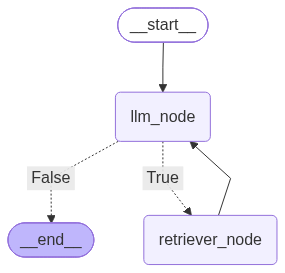

In [406]:
LLM_NODE: str = 'llm_node'
RETRIEVER_NODE: str = 'retriever_node'

graph = StateGraph(AgentState)
graph.add_node(LLM_NODE, call_llm)
graph.add_node(RETRIEVER_NODE, take_action)

graph.add_edge(START, LLM_NODE)

graph.add_conditional_edges(
    LLM_NODE, should_continue,
    {
        True: RETRIEVER_NODE,
        False: END
    }
)
graph.add_edge(RETRIEVER_NODE, LLM_NODE)

rag_agent = graph.compile()
rag_agent

In [407]:
def running_agent():
    while True:
        user_input = input("What is your question?")
        if user_input.lower() in ['exit', 'quit']:
            print("exiting......")
            break
        message = [HumanMessage(content=user_input)]
        result = rag_agent.invoke({"messages": message})
        print(f"Agent response : \n {result['messages'][-1].text}")

    print("Application Exit.....")


running_agent()



Inside Call LLM......................
Inside Call take_action......................
Executing tools call: retriever_tool with input : {'query': 'Bangladesh election document overview summary about'}
Retriever tools is called.................
Tool Result: source 1 : 
 BANGLADESH 13TH GENERAL ELECTION — FEBRUARY 12, 2026
Comprehensive  Political  Analysis  Report

source 2 : 
 BANGLADESH 13TH GENERAL ELECTION — FEBRUARY 12, 2026
Comprehensive  Political  Analysis  Report

source 3 : 
 BANGLADESH 13TH GENERAL ELECTION — FEBRUARY 12, 2026
Comprehensive  Political  Analysis  Report

Tools executed
Inside Call LLM......................
Agent response : 
 Based on the available documents, this document is a **Comprehensive Political Analysis Report** regarding the **Bangladesh 13th General Election**, which is scheduled for **February 12, 2026** (as cited in sources 1, 2, and 3).
Application Exit.....
